Reproduces figures and stats for figure 3 as well as the associated supplemental figure

In [5]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats

In [41]:
# Load the tethered-cell results and parse condition labels from each filename.
results_path = '../tethered-cells/results.csv'
df = pd.read_csv(results_path)
df['filename'] = df['filename'].astype(str).str.strip()

# Four arabinose levels, ordered low -> max induction.
arab_keys = ['2e3', '2e2', '2e1', '2e0']   # 0.002 / 0.02 / 0.2 / 2.0% w/v


def extract_groups(filename):
    '''Parse Ficoll load and arabinose level from a results.csv filename.
    Ficoll is the 0F / 10F / 15F token; some 0% Ficoll files omit it and
    start directly with the arabinose token (2e0 / 2e1 / 2e2 / 2e3).'''
    parts = filename.split('_')
    first = parts[0]
    if first.startswith('2'):              # 0% Ficoll, Ficoll token omitted
        return pd.Series(['0F', first])
    if   '15F' in first: ficoll = '15F'
    elif '10F' in first: ficoll = '10F'
    elif  '0F' in first: ficoll = '0F'
    else:                ficoll = None
    arab = parts[1] if len(parts) > 1 else None
    return pd.Series([ficoll, arab])


def extract_replicate(filename):
    '''Parse biological replicate from the documented filename prefix.'''
    first = filename.split('_', 1)[0]
    if first.startswith('a'):
        return 'replicate 2'
    if first.startswith('b'):
        return 'replicate 3'
    if first.startswith('0'):
        return 'replicate 2'
    return 'replicate 1'


def canonical_filename(filename):
    '''Collapse duplicate _1 analysis entries back to the source video.'''
    return re.sub(r'_1(?=\.avi$)', '', filename)


df[['Ficoll', 'Arabinose']] = df['filename'].apply(extract_groups)
df['Replicate'] = df['filename'].apply(extract_replicate)
df['canonical_filename'] = df['filename'].apply(canonical_filename)

# Curation: reject debris/clumps (object_size) and stuck cells (frequency floor).
filtered = df[(df['object_size'] <= 15) &
              (df['avg_positive_frequency'] >= 0.5)].dropna(
              subset=['avg_positive_frequency', 'object_size']).drop_duplicates(
              subset='canonical_filename')


def freq_array(ficoll, arab):
    '''Per-cell positive rotation frequencies (Hz) for one condition.'''
    m = (filtered['Ficoll'] == ficoll) & (filtered['Arabinose'] == arab)
    return filtered.loc[m, 'avg_positive_frequency'].to_numpy()

def bias_array(ficoll,arab):
    '''Per-cell CCW bias for one condition.'''
    m = (filtered['Ficoll'] == ficoll) & (filtered['Arabinose'] == arab)
    return filtered.loc[m, 'percent_time_positive'].to_numpy()

def replicate_mean_array(ficoll, arab):
    '''Biological-replicate mean frequencies for one condition.'''
    m = (filtered['Ficoll'] == ficoll) & (filtered['Arabinose'] == arab)
    return (filtered.loc[m]
            .groupby('Replicate')['avg_positive_frequency']
            .mean()
            .to_numpy())

def replicate_cell_count_array(ficoll,arab):
    '''Cell count in each replicate'''
    m = (filtered['Ficoll'] == ficoll) & (filtered['Arabinose'] == arab)

    return filtered.loc[m]['Replicate'].value_counts(sort=False).tolist()
    

def replicate_bias_array(ficoll, arab):
    '''Biological-replicate mean bias for one condition.'''
    m = (filtered['Ficoll'] == ficoll) & (filtered['Arabinose'] == arab)
    return (filtered.loc[m]
            .groupby('Replicate')['percent_time_positive']
            .mean()
            .to_numpy())

In [49]:
#replicate counts
count_0F = []
count_10F = []
count_15F = []
for a in arab_keys:
    count_0F.append(replicate_cell_count_array('0F',a))
    count_10F.append(replicate_cell_count_array('10F',a))
    count_15F.append(replicate_cell_count_array('15F',a))

[[12, 34, 5], [12, 83, 18], [14, 40, 10], [18, 78, 8]]


In [9]:
#per-condition cell counts.

total = 0
for ficoll in ['0F', '10F', '15F']:
    counts = [len(freq_array(ficoll, a)) for a in arab_keys]
    total += sum(counts)
    print(f'{ficoll:4s} cells[0.002,0.02,0.2,2%] = {counts}  (n={sum(counts)})')
print(f'total unique cells passing filters = {total}')

print('\nbiological replicate counts by condition')
for ficoll in ['0F', '10F', '15F']:
    for arab in arab_keys:
        n_reps = len(replicate_mean_array(ficoll, arab))
        print(f'{ficoll:4s} {arab:3s}: {n_reps} replicate means')


0F   cells[0.002,0.02,0.2,2%] = [51, 113, 64, 104]  (n=332)
10F  cells[0.002,0.02,0.2,2%] = [30, 50, 35, 31]  (n=146)
15F  cells[0.002,0.02,0.2,2%] = [23, 34, 31, 48]  (n=136)
total unique cells passing filters = 614

biological replicate counts by condition
0F   2e3: 3 replicate means
0F   2e2: 3 replicate means
0F   2e1: 3 replicate means
0F   2e0: 3 replicate means
10F  2e3: 3 replicate means
10F  2e2: 3 replicate means
10F  2e1: 3 replicate means
10F  2e0: 3 replicate means
15F  2e3: 3 replicate means
15F  2e2: 3 replicate means
15F  2e1: 3 replicate means
15F  2e0: 3 replicate means


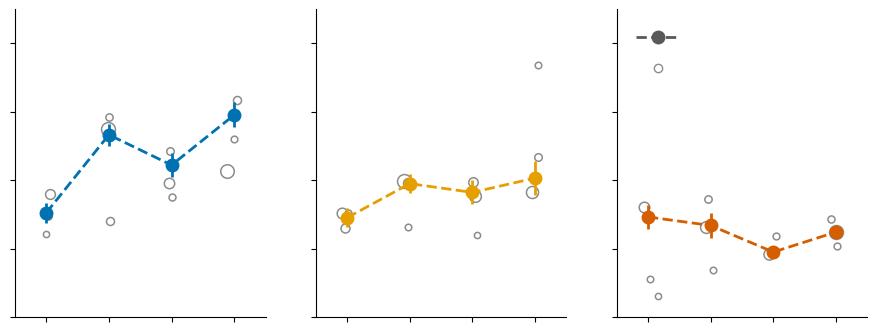

In [61]:
# Figure 4 (main) - single-motor rotation frequency vs arabinose induction for
# tethered NW263 cells at 0 / 10 / 15% Ficoll. Layout parallels Figure 3: three
# panels sharing one y-axis (0-9 Hz) so the slope of the frequency-vs-arabinose
# response can be compared directly across load

np.random.seed(527)  # reproducible jitter for the replicate points

# Wong colorblind-safe palette, mapped to Ficoll load - identical to Figure 3.
c_0F  = '#0072B2'   # blue       - 0% Ficoll  (low load)
c_10F = '#E69F00'   # orange     - 10% Ficoll (intermediate load)
c_15F = '#D55E00'   # vermillion - 15% Ficoll (high load)

# 0.002 / 0.02 / 0.2 / 2% arabinose - log-spaced, so plotted at equal steps.
arab_pos = [0, 1, 2, 3]
arab_lbl = ['0.002', '0.02', '0.2', '2']


def sem(arr):
    '''True standard error of the mean, std / sqrt(n). No /2 fudge factor.'''
    arr = np.asarray(arr, dtype=float)
    return np.std(arr) / np.sqrt(len(arr))

def scale_size(n,min_count,max_count,max_size=100,min_size=20):
    '''Used to scale size of individual replicate dots'''
    if min_count == max_count:
        return (min_size + max_size) / 2

    return min_size + ((n - min_count) / (max_count - min_count)) * (max_size - min_size)

def plot_freq_panel(ax, series, rep_count, color, ficoll_key, letter, title,
                    show_ylabel=False, show_legend=False):
    '''Draw one fully labelled rotation-frequency-vs-arabinose panel.
    series: four per-cell frequency arrays, ordered low -> max arabinose.'''
    means = [np.mean(a) for a in series]
    errs  = [sem(a) for a in series]
    n_min = min(min(sublist) for sublist in rep_count)
    n_max = max(max(sublist) for sublist in rep_count)
    rep_series = [replicate_mean_array(ficoll_key, a) for a in arab_keys]
    for x, rep_means, count_x in zip(arab_pos, rep_series, rep_count):
        for rep_mean, n_cells in zip(rep_means, count_x):
            xj = np.random.normal(x, 0.06)
            size = scale_size(n_cells,n_min,n_max)
            ax.scatter(xj, rep_mean, s=size, facecolors='white', edgecolors='0.55', linewidths=1.1, zorder=2)
    # condition mean +/- SEM with a dashed eye-guide line (a guide, not a fit)
    ax.errorbar(arab_pos, means, yerr=errs, fmt='o', linestyle='--',
                color=color, capsize=0, markersize=9, lw=2, zorder=3)
    # axes
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(0, 9)
    ax.set_xticks(arab_pos,[])
    ax.set_yticks([0, 2, 4, 6, 8],[])
    ax.tick_params(axis='both', labelsize=12)
    # panel letter (left) and condition title (centre)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if show_legend:
        handles = [
            Line2D([0], [0], marker='o', color='0.35', linestyle='--',
                   lw=2, markersize=9),
            Line2D([0], [0], marker='o', color='0.55', linestyle='None',
                   markerfacecolor='white', markersize=6,),
        ]
        ax.legend(handles=handles, loc='upper left', fontsize=15.5,
                  frameon=False, handletextpad=0.4)


# Three load panels in a row, sharing the y-axis.
fig, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=(11, 4), sharey=True)

plot_freq_panel(ax_a, [freq_array('0F',  a) for a in arab_keys], count_0F, c_0F, '0F',
                'a', '0% Ficoll')
plot_freq_panel(ax_b, [freq_array('10F', a) for a in arab_keys], count_10F, c_10F, '10F',
                'b', '10% Ficoll')
plot_freq_panel(ax_c, [freq_array('15F', a) for a in arab_keys], count_15F, c_15F, '15F',
                'c', '15% Ficoll',show_legend=True)

plt.subplots_adjust(wspace=0.2)
plt.savefig('../figure-output/rotation-frequency.pdf', dpi=600,
            bbox_inches='tight')

plt.show()

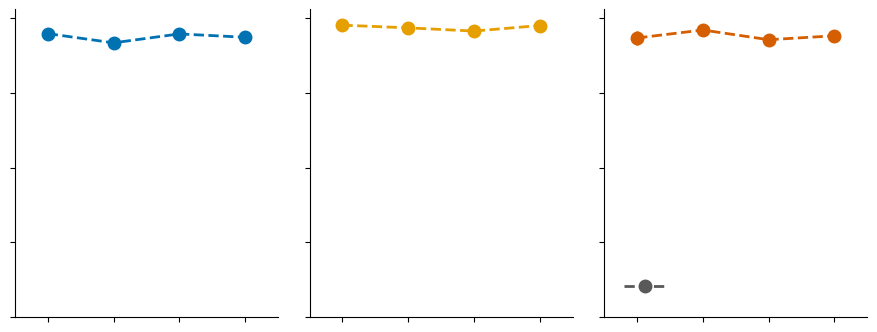

In [11]:
#Supplemental figure for CCW bias, code is very similar to that seen above

def plot_bias_panel(ax, series, color, ficoll_key, letter, title,
                    show_ylabel=False, show_legend=False):
    '''Draw one fully labelled rotation-bias-vs-arabinose panel.
    series: four per-cell frequency arrays, ordered low -> max arabinose.'''
    means = [np.mean(a) for a in series]
    errs  = [sem(a) for a in series]
    rep_series = [replicate_bias_array(ficoll_key, a) for a in arab_keys]
    #for x, rep_means in zip(arab_pos, rep_series):
        #offsets = np.linspace(-0.09, 0.09, len(rep_means)) if len(rep_means) > 1 else [0]
        #ax.scatter(np.asarray(offsets) + x, rep_means, s=28,
                   #facecolors='white', edgecolors='0.55', linewidths=1.1,
                   #zorder=2)
    # condition mean +/- SEM with a dashed eye-guide line (a guide, not a fit)
    ax.errorbar(arab_pos, means, yerr=errs, fmt='o', linestyle='--',
                color=color, capsize=0, markersize=9, lw=2, zorder=3)
    # axes
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(0, 103)
    ax.set_xticks(arab_pos,[])
    ax.set_yticks([0, 25, 50, 75, 100],[])
    ax.tick_params(axis='both', labelsize=12)
    # panel letter (left) and condition title (centre)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if show_legend:
        handles = [
            Line2D([0], [0], marker='o', color='0.35', linestyle='--',
                   lw=2, markersize=9)
            #Line2D([0], [0], marker='o', color='0.55', linestyle='None',
                   #markerfacecolor='white', markersize=6,),
        ]
        ax.legend(handles=handles, loc='lower left', fontsize=15.5,
                  frameon=False, handletextpad=0.4)


# Three load panels in a row, sharing the y-axis.
fig, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=(11, 4), sharey=True)

plot_bias_panel(ax_a, [bias_array('0F',  a) for a in arab_keys], c_0F, '0F',
                'a', '0% Ficoll')
plot_bias_panel(ax_b, [bias_array('10F', a) for a in arab_keys], c_10F, '10F',
                'b', '10% Ficoll')
plot_bias_panel(ax_c, [bias_array('15F', a) for a in arab_keys], c_15F, '15F',
                'c', '15% Ficoll',show_legend=True)

plt.subplots_adjust(wspace=0.12)
plt.savefig('../figure-output/rotation-bias.pdf', dpi=600,
            bbox_inches='tight')
plt.show()

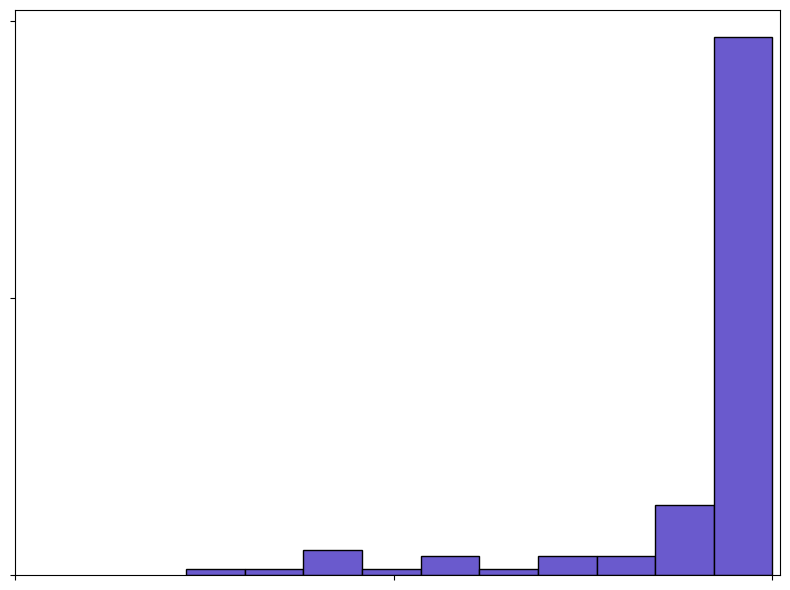

In [55]:
#gives example histogram of CCW bias as seen in the supplement
plt.figure(figsize=(8, 6))
hist = bias_array('0F','2e2')
plt.hist(hist/100,density=True,edgecolor='k',color='slateblue') # <--- probability density (density=True)
plt.xlim(0,1.01)
plt.xticks([0,.5,1],[])
plt.yticks([0,5,10],[])
plt.tight_layout()
plt.savefig('../figure-output/rotation-bias-hist.pdf', dpi=600)

In [11]:
#print p-values
from scipy import stats
#15% F
fvalue, pvalue = stats.f_oneway(freq_array('15F','2e3'),freq_array('15F','2e2'),freq_array('15F','2e1'),freq_array('15F','2e0'))
print(f"15% Ficoll P-value (ANOVA): {pvalue}")
#10% F
fvalue, pvalue = stats.f_oneway(freq_array('10F','2e3'),freq_array('10F','2e2'),freq_array('10F','2e1'),freq_array('10F','2e0'))
print(f"10% Ficoll P-value (ANOVA): {pvalue}")
#0% F
fvalue, pvalue = stats.f_oneway(freq_array('0F','2e3'),freq_array('0F','2e2'),freq_array('0F','2e1'),freq_array('0F','2e0'))
print(f"0% Ficoll P-value (ANOVA): {pvalue}")

15% Ficoll P-value (ANOVA): 0.09132041050153354
10% Ficoll P-value (ANOVA): 0.1489041245832636
0% Ficoll P-value (ANOVA): 4.122461264258294e-06


In [13]:
#calculates ∆s
#original notation while writing manuscript was ∆r_E, now we use ∆s but it is the same value
def delta_R_E(k15,r15,k0,r0):
    '''
    k15 is the array v_k(15%)
    r15 is the array v_r(15%) used as a normalization factor
    k0, r0 are defined similarly
    '''
    rE = np.mean(k15) / np.mean(r15) - np.mean(k0) / np.mean(r0)
    #print(np.mean(k0) / np.mean(r0))
    err1 = ((np.std(k15)/len(k15)) / np.mean(k15))**2 + ((np.std(r15)/len(r15)) / np.mean(r15))**2
    err2 = ((np.std(k0)/len(k0)) / np.mean(k0))**2 + ((np.std(r0)/len(r0)) / np.mean(r0))**2
    err = np.sqrt(err1) + np.sqrt(err2)
    return rE, err

In [17]:
#∆s for 0-10% Ficoll
dR_max = delta_R_E(freq_array('10F','2e0'),freq_array('10F','2e0'),freq_array('0F','2e0'),freq_array('0F','2e0'))  
dR_high = delta_R_E(freq_array('10F','2e1'),freq_array('10F','2e0'),freq_array('0F','2e1'),freq_array('0F','2e0'))  
dR_mid = delta_R_E(freq_array('10F','2e2'),freq_array('10F','2e0'),freq_array('0F','2e2'),freq_array('0F','2e0'))  
dR_low = delta_R_E(freq_array('10F','2e3'),freq_array('10F','2e0'),freq_array('0F','2e3'),freq_array('0F','2e0'))  
print(f"∆s for 0.002% = {dR_low[0]} +/- {dR_low[1]}")
print(f"∆s for 0.02% = {dR_mid[0]} +/- {dR_mid[1]}")
print(f"∆s for 0.2% = {dR_high[0]} +/- {dR_high[1]}")
print(f"∆s for 2.0% = {dR_max[0]} +/- {dR_max[1]}")

∆s for 0.002% = 0.19920719851846347 +/- 0.0423993251376878
∆s for 0.02% = 0.057983080876930715 +/- 0.03229508846590983
∆s for 0.2% = 0.14446989799275078 +/- 0.03872877068354824
∆s for 2.0% = 0.0 +/- 0.03899094925976737


In [19]:
#∆s for 10-15% Ficoll
dR_max = delta_R_E(freq_array('15F','2e0'),freq_array('15F','2e0'),freq_array('10F','2e0'),freq_array('10F','2e0'))  
dR_high = delta_R_E(freq_array('15F','2e1'),freq_array('15F','2e0'),freq_array('10F','2e1'),freq_array('10F','2e0'))  
dR_mid = delta_R_E(freq_array('15F','2e2'),freq_array('15F','2e0'),freq_array('10F','2e2'),freq_array('10F','2e0'))  
dR_low = delta_R_E(freq_array('15F','2e3'),freq_array('15F','2e0'),freq_array('10F','2e3'),freq_array('10F','2e0'))  
print(f"∆s for 0.002% = {dR_low[0]} +/- {dR_low[1]}")
print(f"∆s for 0.02% = {dR_mid[0]} +/- {dR_mid[1]}")
print(f"∆s for 0.2% = {dR_high[0]} +/- {dR_high[1]}")
print(f"∆s for 2.0% = {dR_max[0]} +/- {dR_max[1]}")

∆s for 0.002% = 0.4625502931601544 +/- 0.055683339362631736
∆s for 0.02% = 0.11722807692808979 +/- 0.04954873269982715
∆s for 0.2% = -0.13179773572897324 +/- 0.04595717531684437
∆s for 2.0% = 0.0 +/- 0.04598313665024486


In [19]:
from statsmodels.stats.weightstats import ttost_ind, DescrStatsW, CompareMeans
def TOST(lower,upper,x,y,alpha=0.1):
    p_val, res1, res2 = ttost_ind(x, y, low=lower, upp=upper, usevar="unequal")
    
    # Mean difference (Delta)
    delta = np.mean(x) - np.mean(y)

    # Welch confidence interval for difference
    x_stats = DescrStatsW(x)
    y_stats = DescrStatsW(y)

    cm = CompareMeans(x_stats, y_stats)

    ci_low, ci_high = cm.tconfint_diff(
        alpha=alpha,
        usevar="unequal"
    )

    return round(delta,3), (round(ci_low,3), round(ci_high,3)), round(p_val,3)

In [37]:
print("∆, CI, p-value")
print(f"15F 2e0 vs 2e1: {TOST(-1.3,1.3,replicate_mean_array('15F','2e0'),replicate_mean_array('15F','2e1'))}")
print(f"15F 2e0 vs 2e2: {TOST(-1.3,1.3,replicate_mean_array('15F','2e0'),replicate_mean_array('15F','2e2'))}")
print(f"15F 2e0 vs 2e3: {TOST(-1.3,1.3,replicate_mean_array('15F','2e0'),replicate_mean_array('15F','2e3'))}")
print(f"15F 2e2 vs 2e3: {TOST(-1.3,1.3,replicate_mean_array('15F','2e2'),replicate_mean_array('15F','2e3'))}")
print(f"15F 2e1 vs 2e3: {TOST(-1.3,1.3,replicate_mean_array('15F','2e1'),replicate_mean_array('15F','2e3'))}")
print(f"15F 2e2 vs 2e1: {TOST(-1.3,1.3,replicate_mean_array('15F','2e2'),replicate_mean_array('15F','2e1'))}")

∆, CI, p-value
15F 2e0 vs 2e1: (0.445, (-0.185, 1.074), 0.023)
15F 2e0 vs 2e2: (-0.019, (-1.646, 1.607), 0.078)
15F 2e0 vs 2e3: (0.814, (-1.394, 3.021), 0.305)
15F 2e2 vs 2e3: (0.833, (-1.346, 3.012), 0.333)
15F 2e1 vs 2e3: (0.369, (-1.879, 2.617), 0.182)
15F 2e2 vs 2e1: (0.464, (-1.199, 2.127), 0.149)


In [43]:
print("p-value, ∆, CI")
print(f"10F 2e0 vs 2e1: {TOST(-1.3,1.3,replicate_mean_array('10F','2e0'),replicate_mean_array('10F','2e1'))}")
print(f"10F 2e0 vs 2e2: {TOST(-1.3,1.3,replicate_mean_array('10F','2e0'),replicate_mean_array('10F','2e2'))}")
print(f"10F 2e0 vs 2e3: {TOST(-1.3,1.3,replicate_mean_array('10F','2e0'),replicate_mean_array('10F','2e3'))}")
print(f"10F 2e2 vs 2e3: {TOST(-1.3,1.3,replicate_mean_array('10F','2e2'),replicate_mean_array('10F','2e3'))}")
print(f"10F 2e1 vs 2e3: {TOST(-1.3,1.3,replicate_mean_array('10F','2e1'),replicate_mean_array('10F','2e3'))}")
print(f"10F 2e2 vs 2e1: {TOST(-1.3,1.3,replicate_mean_array('10F','2e2'),replicate_mean_array('10F','2e1'))}")

p-value, ∆, CI
10F 2e0 vs 2e1: (1.944, (-1.021, 4.908), 0.683)
10F 2e0 vs 2e2: (1.725, (-1.257, 4.706), 0.626)
10F 2e0 vs 2e3: (2.331, (-0.856, 5.518), 0.775)
10F 2e2 vs 2e3: (0.606, (-0.582, 1.795), 0.124)
10F 2e1 vs 2e3: (0.388, (-0.898, 1.673), 0.091)
10F 2e2 vs 2e1: (0.219, (-1.145, 1.583), 0.083)


In [ ]:
m